# WBT WSE Gap-Fill Proof Of Concept

Load the 4 m Bryant holes test rasters, inject clumped synthetic WSE gaps, then fill those gaps with a WBT terrain-cost allocation workflow that mirrors the CostGrow phases without an initial resampling step.

## Imports

In [1]:
# 0. Configure imports and the workspace root.
import os, shutil, time, logging, warnings
from importlib import metadata
from pathlib import Path

import numpy as np
import numpy.ma as ma
import pandas as pd
import xarray as xr
import rioxarray
import rasterio
import scipy.ndimage
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, TwoSlopeNorm

from fdsc.alg.costGrow import _distance_fill, _distance_fill_cost_wbt, filter_isolated
from fdsc.coms import set_da_layerNames
from fdsc.hp.wbt import wbt
from fdsc.hp.xr import dataarray_from_masked, xr_to_GeoTiff

os.chdir("/workspace")
warnings.filterwarnings("ignore", message="IProgress not found.*")

## Paths And Controls

In [2]:
# 1. Set paths, cache locations, and run controls.
REPO_DIR = Path("/workspace")
POC_DIR = REPO_DIR / "misc" / "poc"
OUT_DIR = REPO_DIR / "_outputs" / "misc" / "poc" / "wse_gapfill_wbt"
CACHE_DIR = REPO_DIR / ".cache" / "misc" / "poc" / "wse_gapfill_wbt"
RUN_DIR = CACHE_DIR / "wbt"
EXPERIMENT_CACHE_DIR = CACHE_DIR / "experiments"
DATA_DIR = REPO_DIR / "tests" / "data" / "bryantTechnicalNoteResolution2024_holes"

DEM_FP = DATA_DIR / "dem_04m.tif"
WSE_FP = DATA_DIR / "wse_04m.tif"
WSE_MASKED_FP = OUT_DIR / "wse_masked_04m.tif"
WSE_GAPFILLED_FP = OUT_DIR / "wse_gapfilled_04m.tif"
METRICS_FP = OUT_DIR / "gapfill_metrics.csv"
EXPERIMENT_METRICS_FP = OUT_DIR / "gapfill_experiment_metrics.csv"

MASK_SEED = 20240501
MASK_FRAC = 0.10
CLUMP_SIZE = 8
EXPERIMENT_MASK_FRACS = [0.10, 0.20, 0.50]
EXPERIMENT_CLUMP_SIZES = [1, 8, 24]
DISTANCE_FILL_METHOD = "distance_transform_cdt"
DECAY_METHOD_D = {}
CD_BACKEND = "wbt"
DISPLAY_SHAPE = None
LOG_LEVEL = logging.INFO

OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
EXPERIMENT_CACHE_DIR.mkdir(parents=True, exist_ok=True)

logging.basicConfig(level=logging.INFO, format="%(levelname)s.%(name)s: %(message)s", force=True)
logger = logging.getLogger("wse_gapfill_wbt_poc")
logger.setLevel(LOG_LEVEL)
logging.getLogger("rasterio").setLevel(logging.WARNING)

print(f"workspace: {REPO_DIR}")
print(f"data directory: {DATA_DIR}")
print(f"output directory: {OUT_DIR}")
print(f"cache directory: {CACHE_DIR}")
print(f"dem exists: {DEM_FP.exists()}")
print(f"wse exists: {WSE_FP.exists()}")

workspace: /workspace
data directory: /workspace/tests/data/bryantTechnicalNoteResolution2024_holes
output directory: /workspace/_outputs/misc/poc/wse_gapfill_wbt
cache directory: /workspace/.cache/misc/poc/wse_gapfill_wbt
dem exists: True
wse exists: True


## Environment And Raster Diagnostics

In [3]:
# 2. Record package and raster diagnostics from the active environment.
for package_name in ["numpy", "pandas", "xarray", "rioxarray", "rasterio", "matplotlib", "scipy", "scikit-image", "whitebox"]:
    try:
        print(f"{package_name}: {metadata.version(package_name)}")
    except metadata.PackageNotFoundError:
        print(f"{package_name}: not installed")

print(f"WhiteboxTools: {wbt.version().splitlines()[0]}")
print(f"WhiteboxTools exe: {Path(wbt.exe_path) / wbt.exe_name}")

for fp in [DEM_FP, WSE_FP]:
    with rasterio.open(fp) as src:
        print(fp.name)
        print(f"  shape: {(src.height, src.width)}")
        print(f"  cells: {src.height * src.width:,}")
        print(f"  crs: {src.crs}")
        print(f"  res: {src.res}")
        print(f"  nodata: {src.nodata}")
        print(f"  bounds: {tuple(round(v, 3) for v in src.bounds)}")

numpy: 2.4.3
pandas: 3.0.2
xarray: 2026.4.0
rioxarray: 0.22.0
rasterio: 1.5.0
matplotlib: 3.10.8
scipy: 1.17.1
scikit-image: 0.26.0
whitebox: 2.3.6
WhiteboxTools: WhiteboxTools v2.4.0 (c) Dr. John Lindsay 2017-2023
WhiteboxTools exe: /opt/conda/envs/deploy/lib/python3.12/site-packages/whitebox/whitebox_tools
dem_04m.tif
  shape: (1028, 1028)
  cells: 1,056,784
  crs: EPSG:4647
  res: (4.0, 4.0)
  nodata: -9999.0
  bounds: (32366718.0, 5598724.0, 32370830.0, 5602836.0)
wse_04m.tif
  shape: (1028, 1028)
  cells: 1,056,784
  crs: EPSG:4647
  res: (4.0, 4.0)
  nodata: -9999.0
  bounds: (32366718.0, 5598724.0, 32370830.0, 5602836.0)


## Helpers

In [4]:
# 3. Define local notebook helpers for loading, masking, gap-filling, plotting, and reporting.
def load_da(fp):
    """Load a single-band raster and convert nodata values to NaN."""
    da = rioxarray.open_rasterio(fp, masked=False).squeeze().compute()
    nodata = da.rio.nodata
    if nodata is not None:
        da = da.where(da != nodata, np.nan)
    return da.rio.write_nodata(nodata).rio.write_crs(da.rio.crs)


def build_clumped_random_mask(valid_ar, mask_frac, clump_size=8, rng=None):
    """Build a boolean mask from randomly placed square clumps over valid cells."""
    assert valid_ar.ndim == 2
    assert 0.0 < mask_frac < 1.0
    assert int(clump_size) >= 1
    rng = rng or np.random.default_rng()
    clump_size = int(clump_size)
    target_cnt = int(round(int(valid_ar.sum()) * mask_frac))
    mask_ar = np.zeros(valid_ar.shape, dtype=bool)
    valid_idx_ar = np.flatnonzero(valid_ar.ravel())
    assert valid_idx_ar.size > target_cnt

    if clump_size == 1:
        mask_ar.ravel()[rng.choice(valid_idx_ar, size=target_cnt, replace=False)] = True
        actual_cnt = int((mask_ar & valid_ar).sum())
        return mask_ar, {"target_cnt": target_cnt, "actual_cnt": actual_cnt, "iterations": target_cnt}

    valid_yx_ar = np.argwhere(valid_ar)
    height, width = valid_ar.shape
    iter_cnt = 0
    max_iter = max(1_000, int(np.ceil(target_cnt / (clump_size ** 2))) * 200)
    while int((mask_ar & valid_ar).sum()) < target_cnt and iter_cnt < max_iter:
        center_y, center_x = valid_yx_ar[rng.integers(0, valid_yx_ar.shape[0])]
        row0 = int(np.clip(center_y - clump_size // 2, 0, max(height - clump_size, 0)))
        col0 = int(np.clip(center_x - clump_size // 2, 0, max(width - clump_size, 0)))
        row1 = min(row0 + clump_size, height)
        col1 = min(col0 + clump_size, width)
        mask_ar[row0:row1, col0:col1] = True
        iter_cnt += 1

    actual_cnt = int((mask_ar & valid_ar).sum())
    if actual_cnt < target_cnt:
        raise RuntimeError(f"failed to build clumped mask: actual={actual_cnt:,}, target={target_cnt:,}")
    return mask_ar, {"target_cnt": target_cnt, "actual_cnt": actual_cnt, "iterations": iter_cnt}


def downsample_for_display(ar, target_shape=DISPLAY_SHAPE):
    """Nearest-neighbor resample an array for display only."""
    assert ar.ndim == 2
    if target_shape is None or ar.shape == tuple(target_shape):
        return ar
    yi = np.clip(np.round(np.linspace(0, ar.shape[0] - 1, target_shape[0])).astype(int), 0, ar.shape[0] - 1)
    xi = np.clip(np.round(np.linspace(0, ar.shape[1] - 1, target_shape[1])).astype(int), 0, ar.shape[1] - 1)
    return ar[np.ix_(yi, xi)]


def build_hillshade(da, azimuth=315.0, altitude=45.0):
    """Build a simple normalized hillshade from a DEM DataArray."""
    ar = np.asarray(da.data, dtype=float)
    filled_ar = np.where(np.isfinite(ar), ar, np.nanmean(ar))
    res_x, res_y = np.abs(da.rio.resolution())
    gy, gx = np.gradient(filled_ar, res_y, res_x)
    slope = np.pi / 2.0 - np.arctan(np.hypot(gx, gy))
    aspect = np.arctan2(-gx, gy)
    azimuth_rad = np.deg2rad(azimuth)
    altitude_rad = np.deg2rad(altitude)
    shade = (
        np.sin(altitude_rad) * np.sin(slope)
        + np.cos(altitude_rad) * np.cos(slope) * np.cos(azimuth_rad - aspect)
    )
    shade = (shade - np.nanmin(shade)) / (np.nanmax(shade) - np.nanmin(shade))
    return xr.DataArray(shade, coords=da.coords, dims=da.dims, attrs=da.attrs.copy()).rio.write_crs(da.rio.crs)


def add_panel_text(ax, da, lines=None, loc="lower_left"):
    """Add shape/resolution diagnostics and optional panel-specific lines."""
    res_x, res_y = da.rio.resolution()
    text_lines = [
        f"shape: {da.shape[0]:,} x {da.shape[1]:,} px",
        f"res: {abs(res_x):.2f} x {abs(res_y):.2f} m",
    ]
    if lines:
        text_lines.extend(lines)
    y = 0.02 if loc == "lower_left" else 0.98
    va = "bottom" if loc == "lower_left" else "top"
    ax.text(
        0.02,
        y,
        chr(10).join(text_lines),
        transform=ax.transAxes,
        ha="left",
        va=va,
        fontsize=8,
        bbox={"facecolor": "white", "alpha": 0.82, "edgecolor": "0.55", "pad": 4},
    )


def plot_raster(ax, da, title, cmap="viridis", vmin=None, vmax=None, norm=None, underlay_da=None, underlay_alpha=0.45, alpha=None, lines=None, text_loc="lower_left"):
    """Plot a raster DataArray with optional hillshade underlay and diagnostics."""
    if underlay_da is not None:
        underlay_ar = downsample_for_display(np.asarray(underlay_da.data, dtype=float))
        underlay_bounds = underlay_da.rio.bounds()
        ax.imshow(
            underlay_ar,
            extent=(underlay_bounds[0], underlay_bounds[2], underlay_bounds[1], underlay_bounds[3]),
            cmap="Greys",
            interpolation="nearest",
            origin="upper",
            aspect="equal",
            alpha=underlay_alpha,
        )

    ar = downsample_for_display(np.asarray(da.data, dtype=float))
    bounds = da.rio.bounds()
    im = ax.imshow(
        ar,
        extent=(bounds[0], bounds[2], bounds[1], bounds[3]),
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        norm=norm,
        interpolation="nearest",
        origin="upper",
        aspect="equal",
        alpha=alpha,
    )
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    add_panel_text(ax, da, lines=lines, loc=text_loc)
    return im


def calc_metrics(obs_ar, pred_ar, sample_ar):
    """Compute common error metrics for one evaluation sample."""
    assert obs_ar.shape == pred_ar.shape
    assert sample_ar.shape == obs_ar.shape
    sample_ar = sample_ar & np.isfinite(obs_ar) & np.isfinite(pred_ar)
    assert sample_ar.any()
    obs = obs_ar[sample_ar].astype(float)
    pred = pred_ar[sample_ar].astype(float)
    diff = pred - obs
    sst = np.sum((obs - np.mean(obs)) ** 2)
    return {
        "n": int(sample_ar.sum()),
        "bias": float(np.mean(diff)),
        "mae": float(np.mean(np.abs(diff))),
        "rmse": float(np.sqrt(np.mean(diff ** 2))),
        "median_abs": float(np.median(np.abs(diff))),
        "p95_abs": float(np.percentile(np.abs(diff), 95)),
        "max_abs": float(np.max(np.abs(diff))),
        "r2": float(1.0 - np.sum(diff ** 2) / sst) if sst > 0 else np.nan,
    }


def evaluate_gapfill(wse_raw_xr, wse_gapfilled_xr, target_hole_ar):
    """Evaluate gap-filled WSE against the raw WSE over target holes and all valid cells."""
    raw_ar = np.asarray(wse_raw_xr.data, dtype=float)
    gapfilled_ar = np.asarray(wse_gapfilled_xr.data, dtype=float)
    filled_target_eval_ar = target_hole_ar & np.isfinite(gapfilled_ar)
    all_eval_ar = np.isfinite(raw_ar) & np.isfinite(gapfilled_ar)
    metrics_df = pd.DataFrame(
        [
            {"sample": "filled artificial holes", **calc_metrics(raw_ar, gapfilled_ar, filled_target_eval_ar)},
            {"sample": "all original valid intersection", **calc_metrics(raw_ar, gapfilled_ar, all_eval_ar)},
        ]
    )
    metrics_df["target_coverage"] = [
        float(filled_target_eval_ar.sum() / target_hole_ar.sum()),
        float(all_eval_ar.sum() / np.isfinite(raw_ar).sum()),
    ]
    return metrics_df, filled_target_eval_ar, gapfilled_ar - raw_ar


def run_wbt_gapfill(dem_xr, wse_raw_xr, wse_masked_xr, target_hole_ar, run_dir, log):
    """Run the WBT-only CostGrow-style gap-fill on already aligned high-resolution rasters."""
    assert CD_BACKEND == "wbt"
    start = time.perf_counter()

    # Keep observed WSE unchanged, but use above-ground cells as WBT source anchors.
    wse_anchor_xr = wse_masked_xr.where((wse_masked_xr > dem_xr) & dem_xr.notnull(), np.nan)
    wse_anchor_xr.attrs = wse_masked_xr.attrs.copy()
    wse_anchor_xr.attrs["layerName"] = "wse_anchor"
    assert wse_anchor_xr.notnull().any()

    # Build a same-grid terrain-cost raster using fdsc's nearest-value fill helper.
    wse_neutral_ar = _distance_fill(
        wse_anchor_xr.to_masked_array(),
        log=log.getChild("neutral_prefill"),
        method=DISTANCE_FILL_METHOD,
    )
    wse_neutral_xr = dataarray_from_masked(ma.MaskedArray(wse_neutral_ar, mask=dem_xr.isnull().data), wse_anchor_xr)
    wse_neutral_xr.attrs["layerName"] = "wse_neutral_prefill"

    delta_xr = wse_neutral_xr - dem_xr
    cost_xr = xr.where(delta_xr > 0, 1.0, 1.0 + np.abs(delta_xr)).where(dem_xr.notnull(), np.nan)
    cost_xr.attrs = dem_xr.attrs.copy()
    cost_xr.attrs["layerName"] = "terrain_cost"
    cost_xr = cost_xr.rio.write_nodata(dem_xr.rio.nodata).rio.write_crs(dem_xr.rio.crs)
    assert float(cost_xr.min()) >= 0.0

    # Use WBT cost allocation only; no PCRaster fallback.
    if run_dir.exists():
        shutil.rmtree(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)
    wse_alloc_xr = _distance_fill_cost_wbt(wse_anchor_xr, cost_xr, log=log.getChild("wbt"), out_dir=str(run_dir))
    wse_alloc_xr.attrs = wse_raw_xr.attrs.copy()
    wse_alloc_xr.attrs["layerName"] = "wse_cost_alloc"

    cost_distance_xr = load_da(run_dir / "01_outAccum.tif")
    cost_distance_xr.attrs = dem_xr.attrs.copy()
    cost_distance_xr.attrs["layerName"] = "wbt_cost_distance"

    # Fill every WSE nodata cell inside the DEM domain, preserving observed WSE elsewhere.
    nodata_hole_ar = wse_masked_xr.isnull().data & dem_xr.notnull().data
    fill_hole_ar = nodata_hole_ar | (target_hole_ar & dem_xr.notnull().data)
    assert fill_hole_ar.any()

    decay_xr = None
    wse_gapfilled_ar = np.asarray(wse_masked_xr.data, dtype=float).copy()
    wse_alloc_ar = np.asarray(wse_alloc_xr.data, dtype=float)
    if len(DECAY_METHOD_D) > 0:
        decay_ar = np.zeros(wse_alloc_ar.shape, dtype=float)
        distance_ar = np.asarray(cost_distance_xr.data, dtype=float)
        for decay_method, params in DECAY_METHOD_D.items():
            if decay_method != "linear":
                raise KeyError(decay_method)
            decay_ar += np.where(fill_hole_ar & np.isfinite(distance_ar), distance_ar * params["decay_frac"], 0.0)
        decay_xr = xr.DataArray(
            decay_ar,
            coords=wse_raw_xr.coords,
            dims=wse_raw_xr.dims,
            attrs=dem_xr.attrs.copy(),
        ).rio.write_nodata(dem_xr.rio.nodata).rio.write_crs(dem_xr.rio.crs)
        decay_xr.attrs["layerName"] = "wse_gapfill_decay"
        wse_alloc_ar = wse_alloc_ar - decay_ar

    fill_valid_ar = fill_hole_ar & np.isfinite(wse_alloc_ar)
    filled_target_candidate_ar = target_hole_ar & fill_valid_ar
    wse_gapfilled_ar[fill_valid_ar] = wse_alloc_ar[fill_valid_ar]

    wse_gapfilled_xr = xr.DataArray(
        wse_gapfilled_ar,
        coords=wse_raw_xr.coords,
        dims=wse_raw_xr.dims,
        attrs=wse_raw_xr.attrs.copy(),
    ).rio.write_nodata(wse_raw_xr.rio.nodata).rio.write_crs(wse_raw_xr.rio.crs)
    wse_gapfilled_xr.attrs["layerName"] = "wse_gapfilled"

    # Retain the full domain fill; the isolated-region filter would remove valid domain cells.
    connected_bar = wse_gapfilled_xr.notnull().data
    isolated_meta_d = {
        "isolated_region_raw_cnt": 1,
        "isolated_region_sel_cnt": 1,
        "isolated_region_pre_cnt": int(connected_bar.sum()),
        "isolated_region_post_cnt": int(connected_bar.sum()),
    }
    filled_target_after_filter_ar = target_hole_ar & wse_gapfilled_xr.notnull().data
    filled_hole_after_filter_ar = fill_hole_ar & wse_gapfilled_xr.notnull().data

    return {
        "elapsed": time.perf_counter() - start,
        "wse_anchor_xr": wse_anchor_xr,
        "cost_xr": cost_xr,
        "cost_distance_xr": cost_distance_xr,
        "decay_xr": decay_xr,
        "wse_alloc_xr": wse_alloc_xr,
        "wse_gapfilled_xr": wse_gapfilled_xr,
        "nodata_hole_ar": nodata_hole_ar,
        "fill_hole_ar": fill_hole_ar,
        "fill_valid_ar": fill_valid_ar,
        "filled_target_candidate_ar": filled_target_candidate_ar,
        "filled_target_after_filter_ar": filled_target_after_filter_ar,
        "filled_hole_after_filter_ar": filled_hole_after_filter_ar,
        "isolated_meta_d": isolated_meta_d,
        "run_dir": run_dir,
    }

## Load Data And Add Clumped Random Gaps

In [5]:
# 4. Load aligned 4 m rasters and mask WSE cells in random clumps.
dem_xr = load_da(DEM_FP)
wse_raw_xr = load_da(WSE_FP)

assert dem_xr.shape == wse_raw_xr.shape
assert dem_xr.rio.crs == wse_raw_xr.rio.crs
assert dem_xr.rio.resolution() == wse_raw_xr.rio.resolution()
assert dem_xr.rio.bounds() == wse_raw_xr.rio.bounds()

set_da_layerNames({"dem_fine": dem_xr, "wse_raw": wse_raw_xr})
valid_wse_ar = np.isfinite(wse_raw_xr.data)
rng = np.random.default_rng(MASK_SEED)
noise_mask_ar, mask_meta_d = build_clumped_random_mask(valid_wse_ar, MASK_FRAC, clump_size=CLUMP_SIZE, rng=rng)
target_hole_ar = noise_mask_ar & valid_wse_ar
wse_masked_xr = wse_raw_xr.where(~noise_mask_ar)
wse_masked_xr.attrs = wse_raw_xr.attrs.copy()
wse_masked_xr.attrs["layerName"] = "wse_masked"

noise_mask_xr = xr.DataArray(
    np.where(noise_mask_ar, 1.0, np.nan),
    coords=wse_raw_xr.coords,
    dims=wse_raw_xr.dims,
    attrs=wse_raw_xr.attrs.copy(),
).rio.write_nodata(wse_raw_xr.rio.nodata).rio.write_crs(wse_raw_xr.rio.crs)
noise_mask_xr.attrs["layerName"] = "noise_mask"

print(f"random seed: {MASK_SEED}")
print(f"requested mask fraction: {MASK_FRAC:.3f}")
print(f"clump size: {CLUMP_SIZE} px")
print(f"raw finite WSE cells: {int(valid_wse_ar.sum()):,}")
print(f"target finite-WSE mask cells: {mask_meta_d['target_cnt']:,}")
print(f"actual finite-WSE mask cells: {int(target_hole_ar.sum()):,}")
print(f"clump placement iterations: {mask_meta_d['iterations']:,}")
print(f"masked WSE finite cells: {int(wse_masked_xr.notnull().sum()):,}")

random seed: 20240501
requested mask fraction: 0.100
clump size: 8 px
raw finite WSE cells: 168,068
target finite-WSE mask cells: 16,807
actual finite-WSE mask cells: 16,838
clump placement iterations: 285
masked WSE finite cells: 151,230


## Input Plots

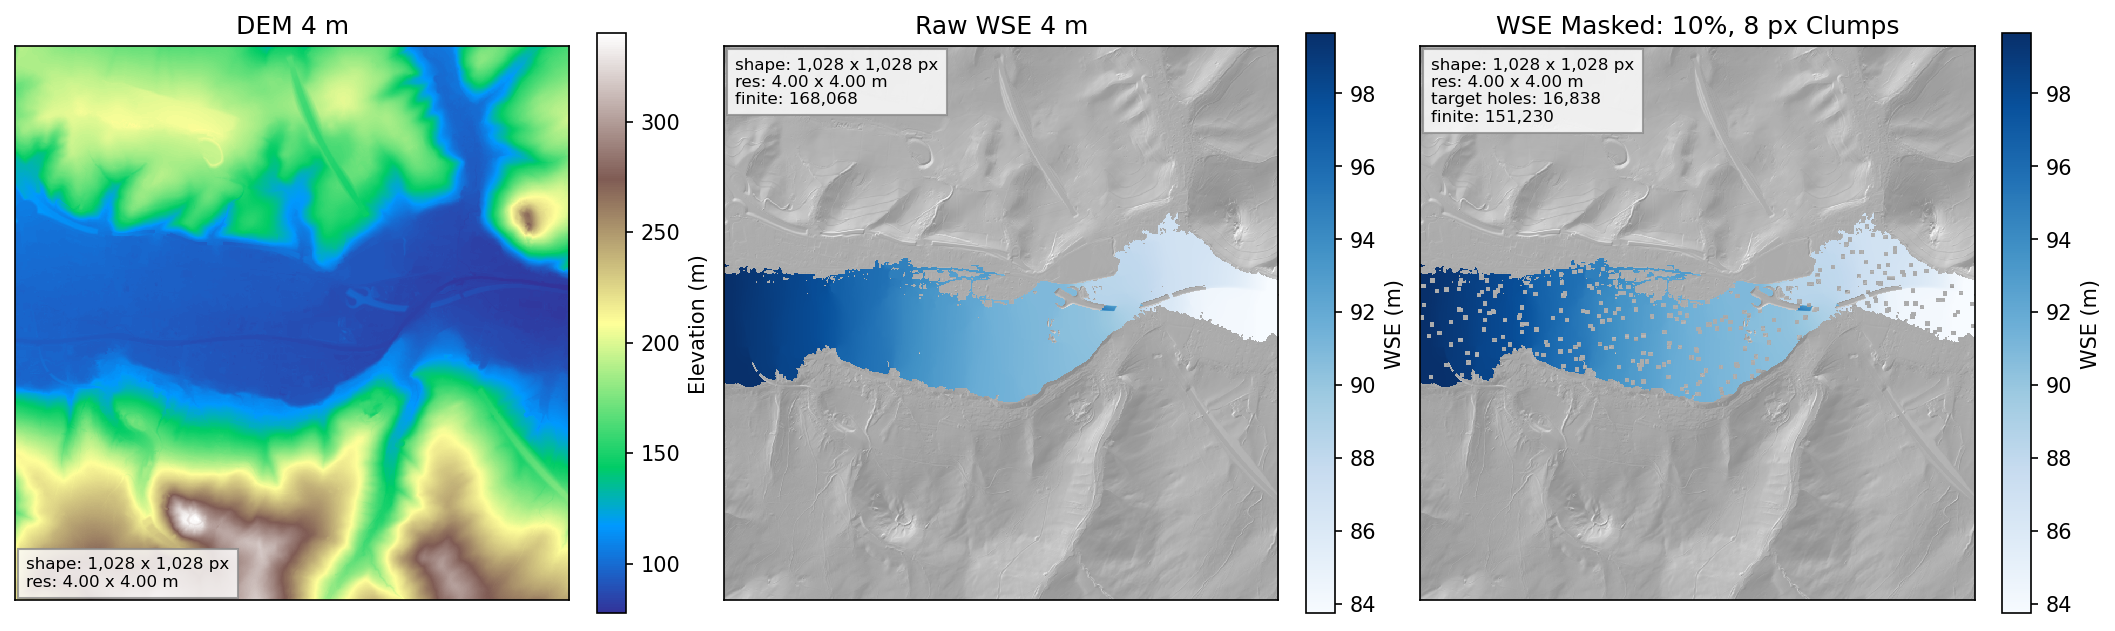

In [6]:
# 5. Plot DEM, raw WSE, and the clumped-mask WSE input.
hillshade_xr = build_hillshade(dem_xr)
wse_cmap = plt.get_cmap("Blues").copy()
wse_cmap.set_bad(alpha=0.0)
wse_values = wse_raw_xr.data[np.isfinite(wse_raw_xr.data)]
wse_vmin, wse_vmax = np.nanpercentile(wse_values, [2, 98])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), constrained_layout=True)

im0 = plot_raster(axes[0], dem_xr, "DEM 4 m", cmap="terrain")
fig.colorbar(im0, ax=axes[0], shrink=0.82, label="Elevation (m)")

im1 = plot_raster(
    axes[1],
    wse_raw_xr,
    "Raw WSE 4 m",
    cmap=wse_cmap,
    vmin=wse_vmin,
    vmax=wse_vmax,
    underlay_da=hillshade_xr,
    lines=[f"finite: {int(wse_raw_xr.notnull().sum()):,}"],
    text_loc="upper_left",
)
fig.colorbar(im1, ax=axes[1], shrink=0.82, label="WSE (m)")

im2 = plot_raster(
    axes[2],
    wse_masked_xr,
    f"WSE Masked: {MASK_FRAC:.0%}, {CLUMP_SIZE} px Clumps",
    cmap=wse_cmap,
    vmin=wse_vmin,
    vmax=wse_vmax,
    underlay_da=hillshade_xr,
    lines=[f"target holes: {int(target_hole_ar.sum()):,}", f"finite: {int(wse_masked_xr.notnull().sum()):,}"],
    text_loc="upper_left",
)
fig.colorbar(im2, ax=axes[2], shrink=0.82, label="WSE (m)")

## WBT Terrain-Cost Gap Fill

In [7]:
# 6. Run a CostGrow-style gap-fill without the initial coarse-to-fine resampling phase.
result_d = run_wbt_gapfill(dem_xr, wse_raw_xr, wse_masked_xr, target_hole_ar, RUN_DIR, logger)
wse_anchor_xr = result_d["wse_anchor_xr"]
cost_xr = result_d["cost_xr"]
cost_distance_xr = result_d["cost_distance_xr"]
decay_xr = result_d["decay_xr"]
wse_gapfilled_xr = result_d["wse_gapfilled_xr"]
nodata_hole_ar = result_d["nodata_hole_ar"]
fill_hole_ar = result_d["fill_hole_ar"]
fill_valid_ar = result_d["fill_valid_ar"]
filled_target_candidate_ar = result_d["filled_target_candidate_ar"]
filled_target_after_filter_ar = result_d["filled_target_after_filter_ar"]
filled_hole_after_filter_ar = result_d["filled_hole_after_filter_ar"]
elapsed = result_d["elapsed"]
isolated_meta_d = result_d["isolated_meta_d"]

xr_to_GeoTiff(wse_masked_xr, str(WSE_MASKED_FP), log=logger.getChild("write"), compress="DEFLATE")
xr_to_GeoTiff(wse_gapfilled_xr, str(WSE_GAPFILLED_FP), log=logger.getChild("write"), compress="DEFLATE")

print(f"elapsed seconds: {elapsed:,.3f}")
print(f"WBT cache directory: {RUN_DIR}")
print(f"decay raster used: {decay_xr is not None}")
print(f"anchor/source cells: {int(wse_anchor_xr.notnull().sum()):,}")
print(f"target holes: {int(target_hole_ar.sum()):,}")
print(f"domain nodata cells: {int(nodata_hole_ar.sum()):,}")
print(f"all fill holes: {int(fill_hole_ar.sum()):,}")
print(f"candidate filled target holes: {int(filled_target_candidate_ar.sum()):,}")
print(f"post-filter filled target holes: {int(filled_target_after_filter_ar.sum()):,}")
print(f"candidate filled all holes: {int(fill_valid_ar.sum()):,}")
print(f"post-filter filled all holes: {int(filled_hole_after_filter_ar.sum()):,}")
print(f"remaining artificial holes: {int((target_hole_ar & wse_gapfilled_xr.isnull().data).sum()):,}")
print(f"remaining all holes: {int((fill_hole_ar & wse_gapfilled_xr.isnull().data).sum()):,}")
print(f"gap-filled finite cells: {int(wse_gapfilled_xr.notnull().sum()):,}")
print(f"masked raster: {WSE_MASKED_FP}")
print(f"gap-filled raster: {WSE_GAPFILLED_FP}")
print("isolated filter metadata:")
for key, value in isolated_meta_d.items():
    print(f"  {key}: {value}")

elapsed seconds: 1.174
WBT cache directory: /workspace/.cache/misc/poc/wse_gapfill_wbt/wbt
decay raster used: False
anchor/source cells: 151,196
target holes: 16,838
domain nodata cells: 905,554
all fill holes: 905,554
candidate filled target holes: 16,838
post-filter filled target holes: 16,838
candidate filled all holes: 905,554
post-filter filled all holes: 905,554
remaining artificial holes: 0
remaining all holes: 0
gap-filled finite cells: 1,056,784
masked raster: /workspace/_outputs/misc/poc/wse_gapfill_wbt/wse_masked_04m.tif
gap-filled raster: /workspace/_outputs/misc/poc/wse_gapfill_wbt/wse_gapfilled_04m.tif
isolated filter metadata:
  isolated_region_raw_cnt: 1
  isolated_region_sel_cnt: 1
  isolated_region_pre_cnt: 1056784
  isolated_region_post_cnt: 1056784


## Workflow Result Plot

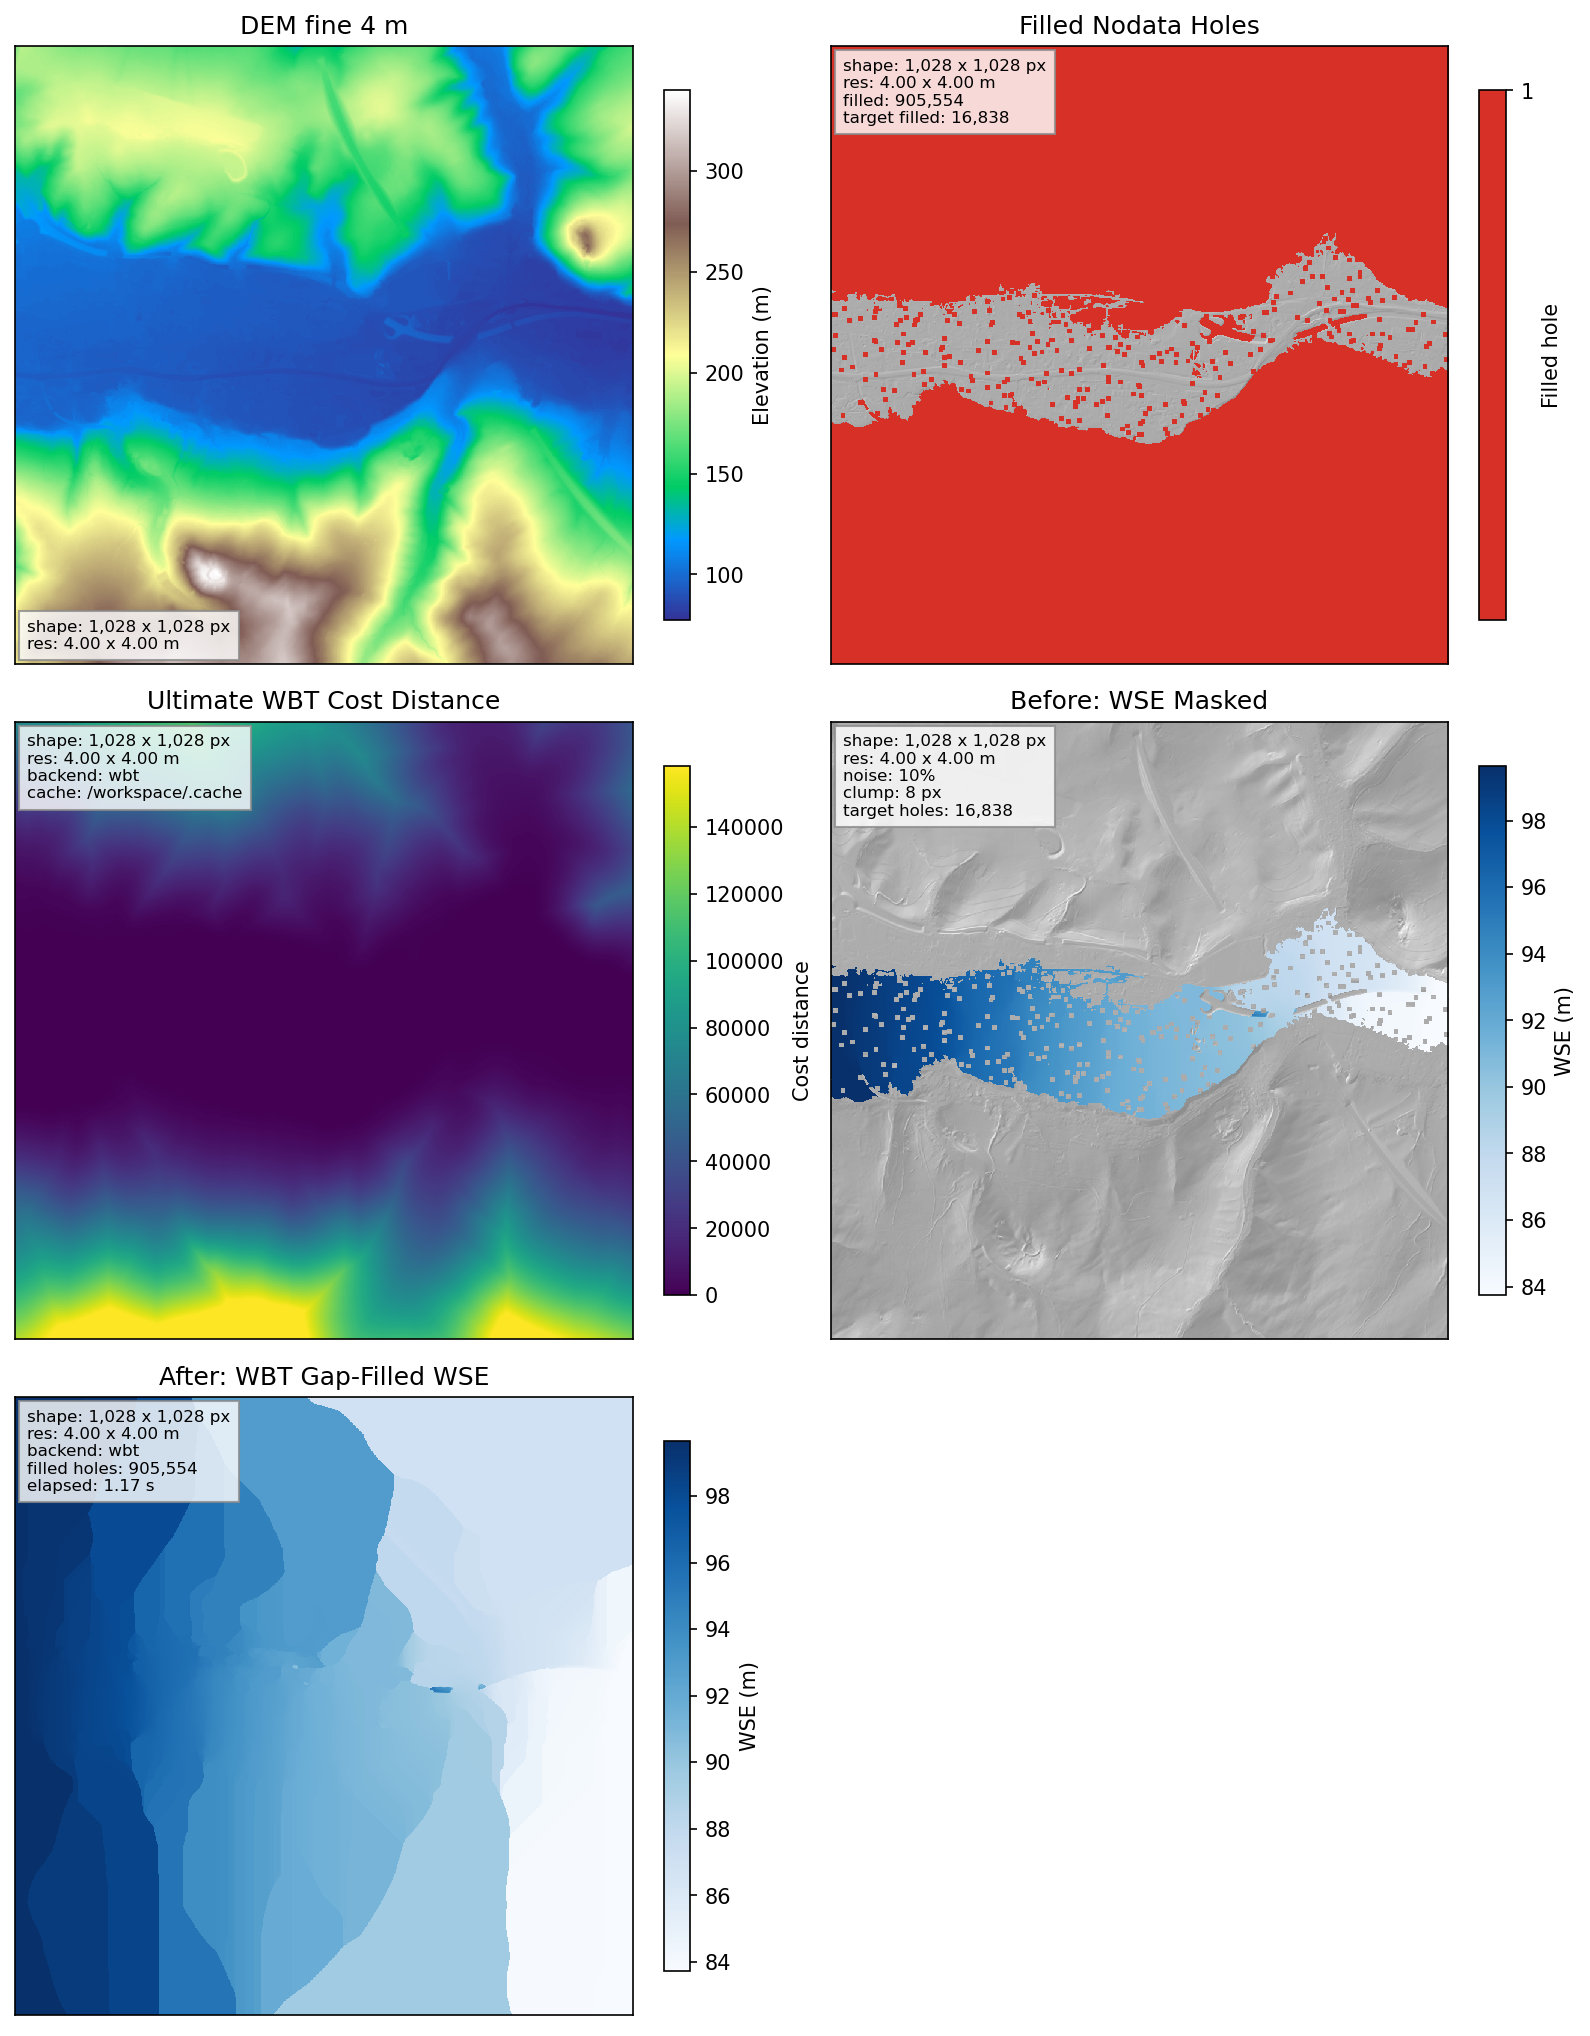

In [8]:
# 7. Plot the POC workflow outputs in the style of the terrain-penalty example.
filled_hole_xr = xr.DataArray(
    np.where(filled_hole_after_filter_ar, 1.0, np.nan),
    coords=wse_raw_xr.coords,
    dims=wse_raw_xr.dims,
    attrs=wse_raw_xr.attrs.copy(),
).rio.write_nodata(wse_raw_xr.rio.nodata).rio.write_crs(wse_raw_xr.rio.crs)
filled_hole_xr.attrs["layerName"] = "filled_holes"

mask_cmap = ListedColormap(["#d73027"])
mask_cmap.set_bad(alpha=0.0)
distance_vmax = float(np.nanpercentile(cost_distance_xr.data[np.isfinite(cost_distance_xr.data)], 98))
decay_vmax = None if decay_xr is None else float(np.nanpercentile(decay_xr.data[np.isfinite(decay_xr.data)], 98))
masked_text = [f"noise: {MASK_FRAC:.0%}", f"clump: {CLUMP_SIZE} px", f"target holes: {int(target_hole_ar.sum()):,}"]
after_text = [f"backend: {CD_BACKEND}", f"filled holes: {int(filled_hole_after_filter_ar.sum()):,}", f"elapsed: {elapsed:,.2f} s"]

panel_cnt = 6 if decay_xr is not None else 5
nrows = int(np.ceil(panel_cnt / 2))
fig, axes = plt.subplots(nrows, 2, figsize=(10.5, 4.5 * nrows), constrained_layout=True)
axes_ar = np.asarray(axes).reshape(-1)
panel_i = 0

im = plot_raster(axes_ar[panel_i], dem_xr, "DEM fine 4 m", cmap="terrain")
fig.colorbar(im, ax=axes_ar[panel_i], shrink=0.84, label="Elevation (m)")
panel_i += 1

im = plot_raster(
    axes_ar[panel_i],
    filled_hole_xr,
    "Filled Nodata Holes",
    cmap=mask_cmap,
    vmin=0.0,
    vmax=1.0,
    underlay_da=hillshade_xr,
    lines=[f"filled: {int(filled_hole_after_filter_ar.sum()):,}", f"target filled: {int(filled_target_after_filter_ar.sum()):,}"],
    text_loc="upper_left",
)
fig.colorbar(im, ax=axes_ar[panel_i], shrink=0.84, ticks=[1], label="Filled hole")
panel_i += 1

im = plot_raster(
    axes_ar[panel_i],
    cost_distance_xr,
    "Ultimate WBT Cost Distance",
    cmap="viridis",
    vmin=0.0,
    vmax=distance_vmax,
    lines=[f"backend: {CD_BACKEND}", "cache: /workspace/.cache"],
    text_loc="upper_left",
)
fig.colorbar(im, ax=axes_ar[panel_i], shrink=0.84, label="Cost distance")
panel_i += 1

if decay_xr is not None:
    im = plot_raster(
        axes_ar[panel_i],
        decay_xr,
        "Decay Raster",
        cmap="magma",
        vmin=0.0,
        vmax=decay_vmax,
        lines=[f"methods: {', '.join(DECAY_METHOD_D.keys())}"],
        text_loc="upper_left",
    )
    fig.colorbar(im, ax=axes_ar[panel_i], shrink=0.84, label="WSE decay (m)")
    panel_i += 1

im = plot_raster(
    axes_ar[panel_i],
    wse_masked_xr,
    "Before: WSE Masked",
    cmap=wse_cmap,
    vmin=wse_vmin,
    vmax=wse_vmax,
    underlay_da=hillshade_xr,
    lines=masked_text,
    text_loc="upper_left",
)
fig.colorbar(im, ax=axes_ar[panel_i], shrink=0.84, label="WSE (m)")
panel_i += 1

im = plot_raster(
    axes_ar[panel_i],
    wse_gapfilled_xr,
    "After: WBT Gap-Filled WSE",
    cmap=wse_cmap,
    vmin=wse_vmin,
    vmax=wse_vmax,
    underlay_da=hillshade_xr,
    lines=after_text,
    text_loc="upper_left",
)
fig.colorbar(im, ax=axes_ar[panel_i], shrink=0.84, label="WSE (m)")
panel_i += 1

for ax in axes_ar[panel_i:]:
    ax.set_axis_off()

## Evaluation Metrics

In [9]:
# 8. Compare the gap-filled WSE against the original raw 4 m WSE.
metrics_df, filled_target_eval_ar, diff_ar = evaluate_gapfill(wse_raw_xr, wse_gapfilled_xr, target_hole_ar)
metrics_df.to_csv(METRICS_FP, index=False)

print(metrics_df.round(6).to_string(index=False))
print(f"metrics: {METRICS_FP}")
metrics_df

                         sample      n     bias      mae     rmse  median_abs  p95_abs  max_abs       r2  target_coverage
        filled artificial holes  16838 0.002467 0.018703 0.080554    0.007996 0.062004 4.094002 0.999688              1.0
all original valid intersection 168068 0.000247 0.001874 0.025497    0.000000 0.007996 4.094002 0.999970              1.0
metrics: /workspace/_outputs/misc/poc/wse_gapfill_wbt/gapfill_metrics.csv


                            sample       n  ...        r2  target_coverage
0          filled artificial holes   16838  ...  0.999688              1.0
1  all original valid intersection  168068  ...  0.999970              1.0

[2 rows x 10 columns]

## Difference Raster

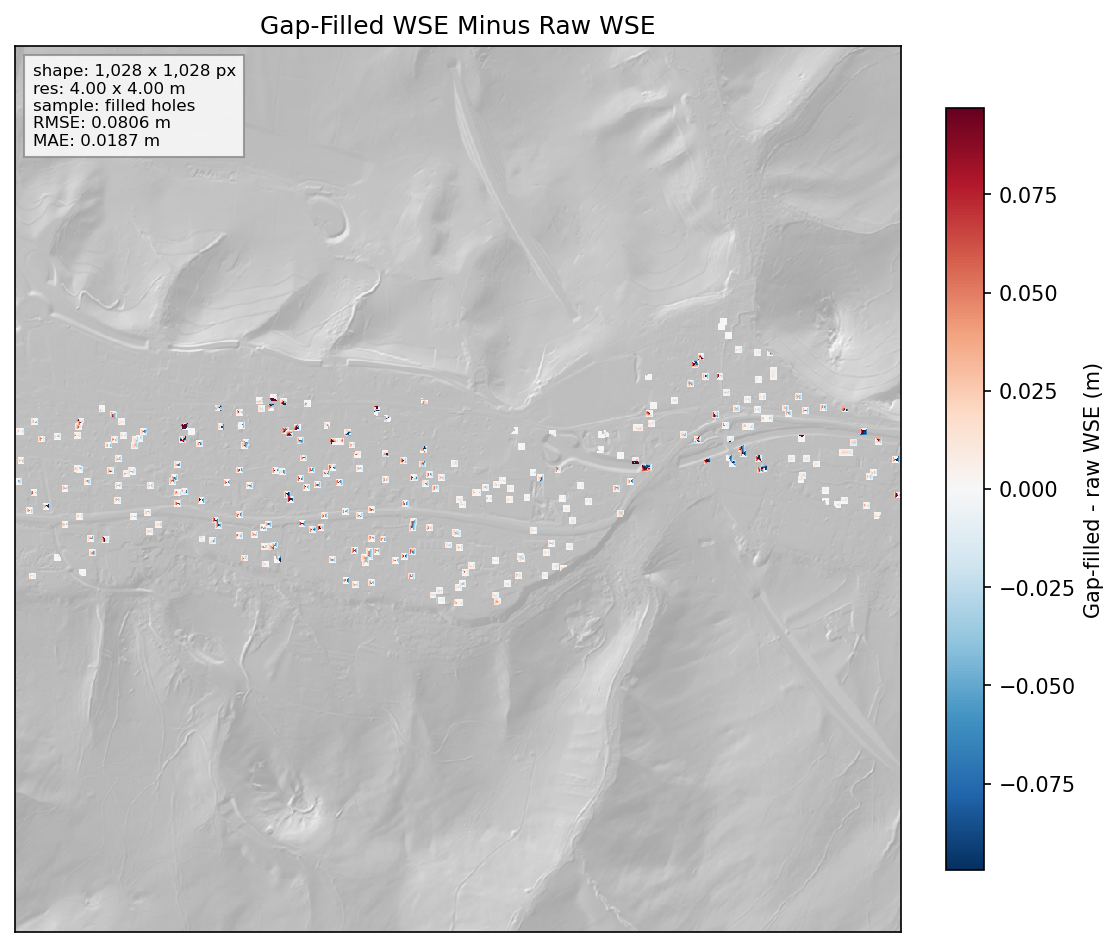

In [10]:
# 9. Plot gap-filled minus raw WSE on the artificial holes.
diff_target_xr = xr.DataArray(
    np.where(filled_target_eval_ar, diff_ar, np.nan),
    coords=wse_raw_xr.coords,
    dims=wse_raw_xr.dims,
    attrs=wse_raw_xr.attrs.copy(),
).rio.write_nodata(wse_raw_xr.rio.nodata).rio.write_crs(wse_raw_xr.rio.crs)
diff_target_xr.attrs["layerName"] = "wse_gapfill_diff"

abs_diff = np.abs(diff_target_xr.data[np.isfinite(diff_target_xr.data)])
diff_lim = float(np.nanpercentile(abs_diff, 98)) if abs_diff.size else 1.0
diff_lim = max(diff_lim, 0.01)

fig, ax = plt.subplots(1, 1, figsize=(7.5, 6.2), constrained_layout=True)
im = plot_raster(
    ax,
    diff_target_xr,
    "Gap-Filled WSE Minus Raw WSE",
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-diff_lim, vcenter=0.0, vmax=diff_lim),
    underlay_da=hillshade_xr,
    underlay_alpha=0.35,
    lines=[f"sample: filled holes", f"RMSE: {metrics_df.loc[0, 'rmse']:.4f} m", f"MAE: {metrics_df.loc[0, 'mae']:.4f} m"],
    text_loc="upper_left",
)
fig.colorbar(im, ax=ax, shrink=0.86, label="Gap-filled - raw WSE (m)")

## WSE-DEM Breaks

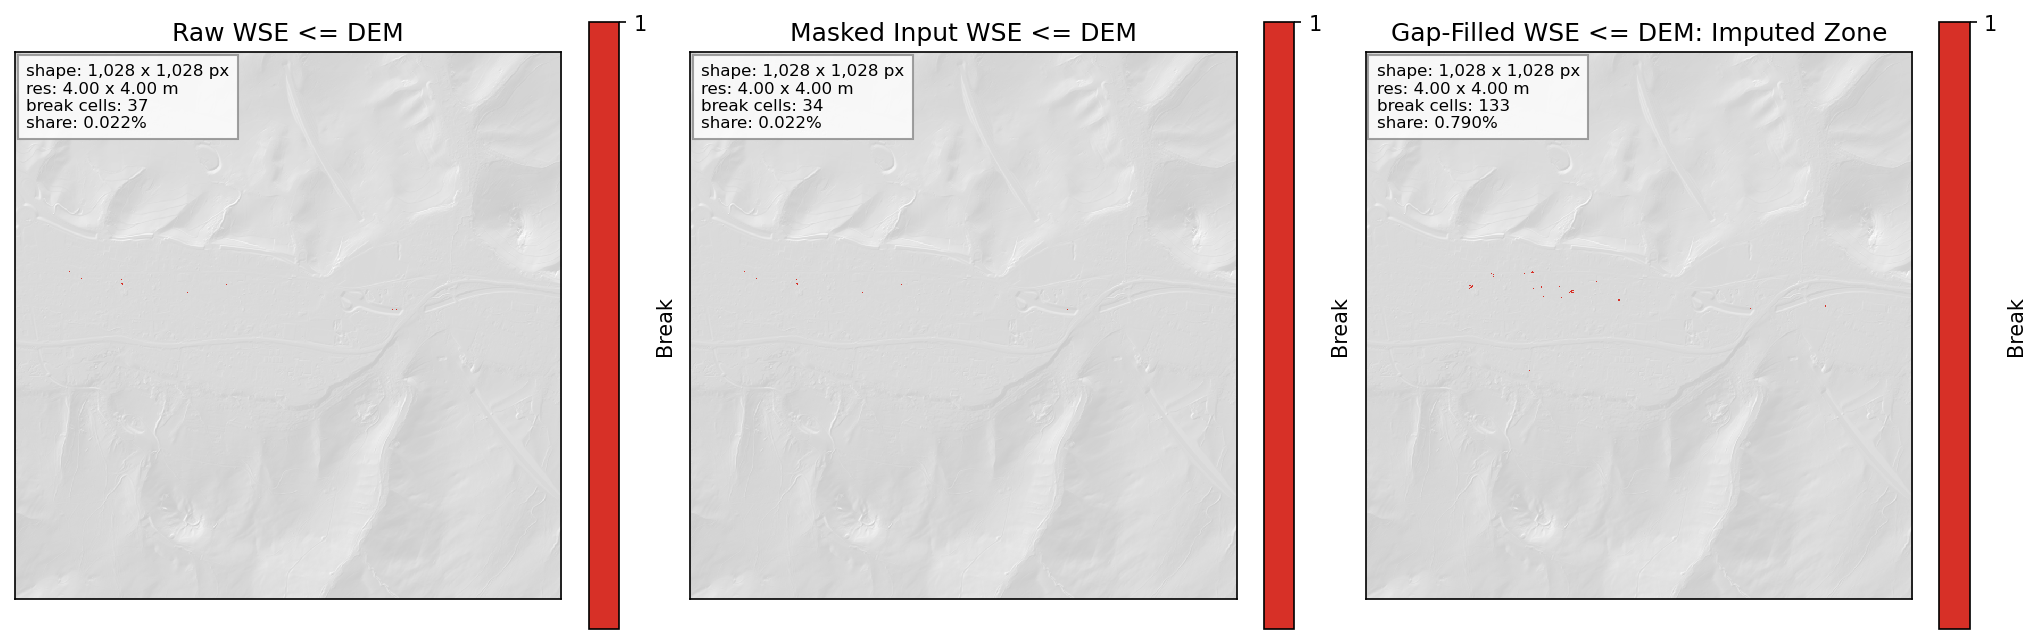

In [11]:
# 10. Highlight cells where WSE is below or equal to the DEM for raw, masked input, and imputed zone.
raw_ar = np.asarray(wse_raw_xr.data, dtype=float)
masked_ar = np.asarray(wse_masked_xr.data, dtype=float)
gapfilled_ar = np.asarray(wse_gapfilled_xr.data, dtype=float)
dem_ar = np.asarray(dem_xr.data, dtype=float)

raw_break_ar = (raw_ar <= dem_ar) & np.isfinite(raw_ar) & np.isfinite(dem_ar)
masked_break_ar = (masked_ar <= dem_ar) & np.isfinite(masked_ar) & np.isfinite(dem_ar)
gapfilled_break_impute_ar = (gapfilled_ar <= dem_ar) & np.isfinite(gapfilled_ar) & np.isfinite(dem_ar) & target_hole_ar

raw_break_xr = xr.DataArray(
    np.where(raw_break_ar, 1.0, np.nan),
    coords=wse_raw_xr.coords,
    dims=wse_raw_xr.dims,
    attrs=wse_raw_xr.attrs.copy(),
).rio.write_nodata(wse_raw_xr.rio.nodata).rio.write_crs(wse_raw_xr.rio.crs)
raw_break_xr.attrs["layerName"] = "raw_wse_dem_breaks"

masked_break_xr = xr.DataArray(
    np.where(masked_break_ar, 1.0, np.nan),
    coords=wse_raw_xr.coords,
    dims=wse_raw_xr.dims,
    attrs=wse_raw_xr.attrs.copy(),
).rio.write_nodata(wse_raw_xr.rio.nodata).rio.write_crs(wse_raw_xr.rio.crs)
masked_break_xr.attrs["layerName"] = "masked_wse_dem_breaks"

gapfilled_break_xr = xr.DataArray(
    np.where(gapfilled_break_impute_ar, 1.0, np.nan),
    coords=wse_raw_xr.coords,
    dims=wse_raw_xr.dims,
    attrs=wse_raw_xr.attrs.copy(),
).rio.write_nodata(wse_raw_xr.rio.nodata).rio.write_crs(wse_raw_xr.rio.crs)
gapfilled_break_xr.attrs["layerName"] = "gapfilled_impute_wse_dem_breaks"

break_cmap = ListedColormap(["#d73027"])
break_cmap.set_bad(alpha=0.0)
raw_break_pct = raw_break_ar.sum() / np.isfinite(raw_ar).sum() * 100.0
masked_break_pct = masked_break_ar.sum() / np.isfinite(masked_ar).sum() * 100.0
gap_break_pct = gapfilled_break_impute_ar.sum() / max(int(filled_target_eval_ar.sum()), 1) * 100.0

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.9), constrained_layout=True)

im0 = plot_raster(
    axes[0],
    raw_break_xr,
    "Raw WSE <= DEM",
    cmap=break_cmap,
    vmin=0.0,
    vmax=1.0,
    underlay_da=hillshade_xr,
    underlay_alpha=0.2,
    lines=[f"break cells: {int(raw_break_ar.sum()):,}", f"share: {raw_break_pct:.3f}%"],
    text_loc="upper_left",
)
fig.colorbar(im0, ax=axes[0], shrink=0.84, ticks=[1], label="Break")

im1 = plot_raster(
    axes[1],
    masked_break_xr,
    "Masked Input WSE <= DEM",
    cmap=break_cmap,
    vmin=0.0,
    vmax=1.0,
    underlay_da=hillshade_xr,
    underlay_alpha=0.2,
    lines=[f"break cells: {int(masked_break_ar.sum()):,}", f"share: {masked_break_pct:.3f}%"],
    text_loc="upper_left",
)
fig.colorbar(im1, ax=axes[1], shrink=0.84, ticks=[1], label="Break")

im2 = plot_raster(
    axes[2],
    gapfilled_break_xr,
    "Gap-Filled WSE <= DEM: Imputed Zone",
    cmap=break_cmap,
    vmin=0.0,
    vmax=1.0,
    underlay_da=hillshade_xr,
    underlay_alpha=0.2,
    lines=[f"break cells: {int(gapfilled_break_impute_ar.sum()):,}", f"share: {gap_break_pct:.3f}%"],
    text_loc="upper_left",
)
fig.colorbar(im2, ax=axes[2], shrink=0.84, ticks=[1], label="Break")

## Synthetic Noise Experiment Sweep

In [12]:
# 11. Run 9 WBT-only experiments across noise fractions and clump sizes.
experiment_l = []
valid_wse_ar = np.isfinite(wse_raw_xr.data)
run_i = 0

for mask_frac in EXPERIMENT_MASK_FRACS:
    for clump_size in EXPERIMENT_CLUMP_SIZES:
        run_i += 1
        label = f"p{int(mask_frac * 100):02d}_c{int(clump_size):02d}"
        rng = np.random.default_rng(MASK_SEED + run_i)
        exp_mask_ar, exp_mask_meta_d = build_clumped_random_mask(valid_wse_ar, mask_frac, clump_size=clump_size, rng=rng)
        exp_target_hole_ar = exp_mask_ar & valid_wse_ar
        exp_wse_masked_xr = wse_raw_xr.where(~exp_mask_ar)
        exp_wse_masked_xr.attrs = wse_raw_xr.attrs.copy()
        exp_wse_masked_xr.attrs["layerName"] = "wse_masked"

        exp_result_d = run_wbt_gapfill(
            dem_xr,
            wse_raw_xr,
            exp_wse_masked_xr,
            exp_target_hole_ar,
            EXPERIMENT_CACHE_DIR / label,
            logger.getChild(label),
        )
        exp_metrics_df, exp_filled_eval_ar, exp_diff_ar = evaluate_gapfill(
            wse_raw_xr,
            exp_result_d["wse_gapfilled_xr"],
            exp_target_hole_ar,
        )
        hole_metrics_s = exp_metrics_df.set_index("sample").loc["filled artificial holes"]
        meta_d = {
            "label": label,
            "mask_frac": mask_frac,
            "clump_size": clump_size,
            "mask_target_cnt": exp_mask_meta_d["target_cnt"],
            "mask_actual_cnt": int(exp_target_hole_ar.sum()),
            "mask_iterations": exp_mask_meta_d["iterations"],
            "candidate_fill_cnt": int(exp_result_d["filled_target_candidate_ar"].sum()),
            "post_filter_fill_cnt": int(exp_result_d["filled_target_after_filter_ar"].sum()),
            "candidate_hole_fill_cnt": int(exp_result_d["fill_valid_ar"].sum()),
            "post_filter_hole_fill_cnt": int(exp_result_d["filled_hole_after_filter_ar"].sum()),
            "elapsed": exp_result_d["elapsed"],
            "cache_dir": str(EXPERIMENT_CACHE_DIR / label),
        }
        experiment_l.append(
            {
                **meta_d,
                "wse_masked_xr": exp_wse_masked_xr,
                "wse_gapfilled_xr": exp_result_d["wse_gapfilled_xr"],
                "cost_distance_xr": exp_result_d["cost_distance_xr"],
                "target_hole_ar": exp_target_hole_ar,
                "filled_eval_ar": exp_filled_eval_ar,
                "diff_ar": exp_diff_ar,
                "metrics_df": exp_metrics_df,
                "rmse": float(hole_metrics_s["rmse"]),
                "mae": float(hole_metrics_s["mae"]),
                "bias": float(hole_metrics_s["bias"]),
                "target_coverage": float(hole_metrics_s["target_coverage"]),
            }
        )
        print(
            f"{label}: target={int(exp_target_hole_ar.sum()):,}, "
            f"filled={int(exp_result_d['filled_target_after_filter_ar'].sum()):,}, "
            f"rmse={float(hole_metrics_s['rmse']):.4f}, elapsed={exp_result_d['elapsed']:.2f}s"
        )

experiment_metrics_df = pd.DataFrame(
    [
        {k: v for k, v in experiment_d.items() if not k.endswith("_xr") and not k.endswith("_ar") and k != "metrics_df"}
        for experiment_d in experiment_l
    ]
)
experiment_metrics_df.to_csv(EXPERIMENT_METRICS_FP, index=False)
print(f"experiment metrics: {EXPERIMENT_METRICS_FP}")
experiment_metrics_df.round(6)

p10_c01: target=16,807, filled=16,807, rmse=0.0525, elapsed=1.14s
p10_c08: target=16,829, filled=16,829, rmse=0.0772, elapsed=1.16s
p10_c24: target=17,001, filled=17,001, rmse=0.0803, elapsed=1.24s
p20_c01: target=33,614, filled=33,614, rmse=0.0523, elapsed=0.96s
p20_c08: target=33,625, filled=33,625, rmse=0.0951, elapsed=0.93s
p20_c24: target=33,757, filled=33,757, rmse=0.1949, elapsed=0.91s
p50_c01: target=84,034, filled=84,034, rmse=0.0451, elapsed=0.95s
p50_c08: target=84,072, filled=84,072, rmse=0.0877, elapsed=0.92s
p50_c24: target=84,061, filled=84,061, rmse=0.2170, elapsed=0.90s
experiment metrics: /workspace/_outputs/misc/poc/wse_gapfill_wbt/gapfill_experiment_metrics.csv


     label  mask_frac  clump_size  ...       mae      bias  target_coverage
0  p10_c01        0.1           1  ...  0.007087 -0.000962              1.0
1  p10_c08        0.1           8  ...  0.018878 -0.001211              1.0
2  p10_c24        0.1          24  ...  0.036428  0.003521              1.0
3  p20_c01        0.2           1  ...  0.007891 -0.002353              1.0
4  p20_c08        0.2           8  ...  0.020251 -0.000800              1.0
5  p20_c24        0.2          24  ...  0.048255 -0.013246              1.0
6  p50_c01        0.5           1  ...  0.009447 -0.002290              1.0
7  p50_c08        0.5           8  ...  0.024071  0.000458              1.0
8  p50_c24        0.5          24  ...  0.071044 -0.002692              1.0

[9 rows x 16 columns]

## P50 C24 Gap-Fill Detail

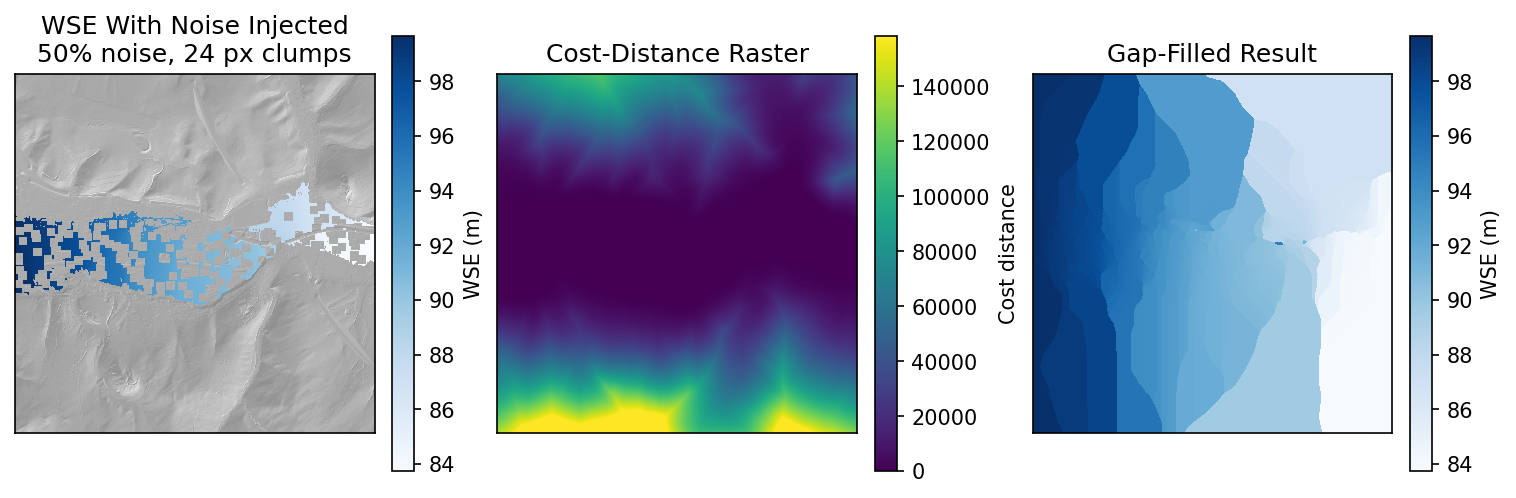

In [13]:
# 12. Show the high-noise, large-clump workflow detail requested for review.
selected_experiment_d = next(experiment_d for experiment_d in experiment_l if experiment_d["label"] == "p50_c24")
selected_masked_xr = selected_experiment_d["wse_masked_xr"]
selected_distance_xr = selected_experiment_d["cost_distance_xr"]
selected_gapfilled_xr = selected_experiment_d["wse_gapfilled_xr"]
selected_distance_vmax = float(np.nanpercentile(selected_distance_xr.data[np.isfinite(selected_distance_xr.data)], 98))
detail_bounds = selected_masked_xr.rio.bounds()

fig, axes = plt.subplots(1, 3, figsize=(10, 3.8), constrained_layout=True)

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])

axes[0].imshow(
    downsample_for_display(np.asarray(hillshade_xr.data, dtype=float)),
    extent=(detail_bounds[0], detail_bounds[2], detail_bounds[1], detail_bounds[3]),
    cmap="Greys",
    interpolation="nearest",
    origin="upper",
    aspect="equal",
    alpha=0.45,
)
im0 = axes[0].imshow(
    downsample_for_display(np.asarray(selected_masked_xr.data, dtype=float)),
    extent=(detail_bounds[0], detail_bounds[2], detail_bounds[1], detail_bounds[3]),
    cmap=wse_cmap,
    vmin=wse_vmin,
    vmax=wse_vmax,
    interpolation="nearest",
    origin="upper",
    aspect="equal",
)
axes[0].set_title("WSE With Noise Injected\n50% noise, 24 px clumps")
fig.colorbar(im0, ax=axes[0], shrink=0.78, label="WSE (m)")

im1 = axes[1].imshow(
    downsample_for_display(np.asarray(selected_distance_xr.data, dtype=float)),
    extent=(detail_bounds[0], detail_bounds[2], detail_bounds[1], detail_bounds[3]),
    cmap="viridis",
    vmin=0.0,
    vmax=selected_distance_vmax,
    interpolation="nearest",
    origin="upper",
    aspect="equal",
)
axes[1].set_title("Cost-Distance Raster")
fig.colorbar(im1, ax=axes[1], shrink=0.78, label="Cost distance")

axes[2].imshow(
    downsample_for_display(np.asarray(hillshade_xr.data, dtype=float)),
    extent=(detail_bounds[0], detail_bounds[2], detail_bounds[1], detail_bounds[3]),
    cmap="Greys",
    interpolation="nearest",
    origin="upper",
    aspect="equal",
    alpha=0.45,
)
im2 = axes[2].imshow(
    downsample_for_display(np.asarray(selected_gapfilled_xr.data, dtype=float)),
    extent=(detail_bounds[0], detail_bounds[2], detail_bounds[1], detail_bounds[3]),
    cmap=wse_cmap,
    vmin=wse_vmin,
    vmax=wse_vmax,
    interpolation="nearest",
    origin="upper",
    aspect="equal",
)
axes[2].set_title("Gap-Filled Result")
fig.colorbar(im2, ax=axes[2], shrink=0.78, label="WSE (m)")

## Experiment Sweep Plot

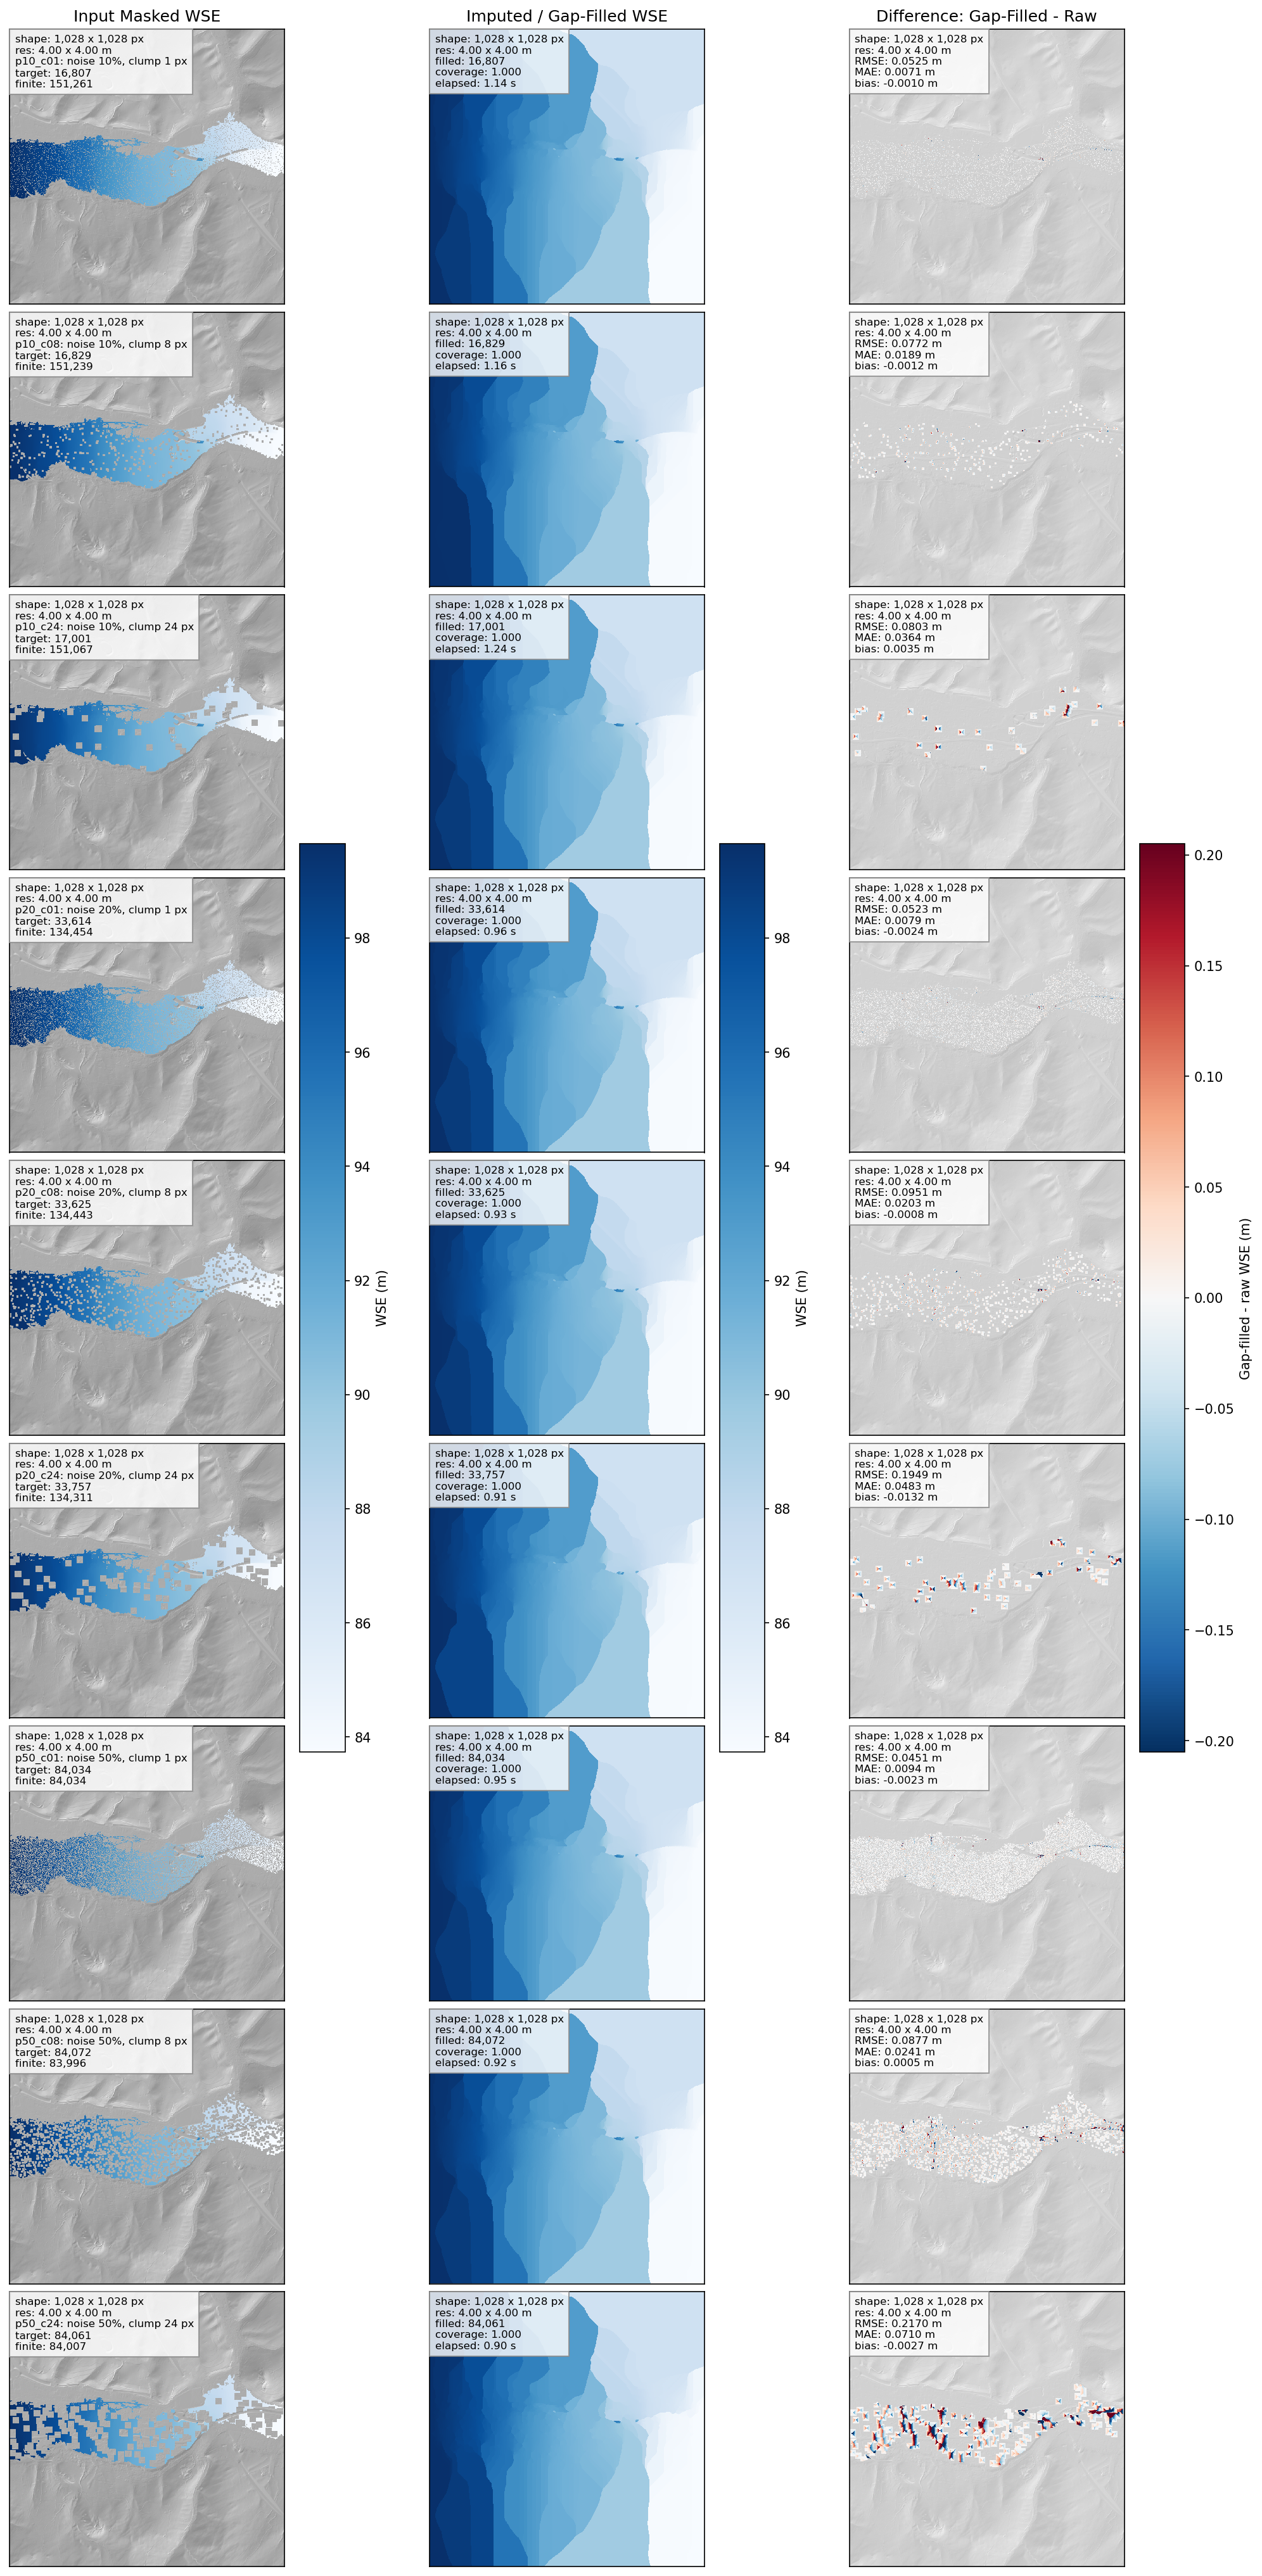

In [14]:
# 13. Plot each experiment as masked input, gap-filled WSE, and gap-filled minus raw WSE.
all_abs_diff_ar = np.concatenate([
    np.abs(experiment_d["diff_ar"][experiment_d["filled_eval_ar"]]).ravel()
    for experiment_d in experiment_l
    if experiment_d["filled_eval_ar"].any()
])
exp_diff_lim = max(float(np.nanpercentile(all_abs_diff_ar, 98)), 0.01)

fig, axes = plt.subplots(len(experiment_l), 3, figsize=(13.5, 3.0 * len(experiment_l)), constrained_layout=True)

for row, experiment_d in enumerate(experiment_l):
    exp_masked_xr = experiment_d["wse_masked_xr"]
    exp_gapfilled_xr = experiment_d["wse_gapfilled_xr"]
    exp_diff_xr = xr.DataArray(
        np.where(experiment_d["filled_eval_ar"], experiment_d["diff_ar"], np.nan),
        coords=wse_raw_xr.coords,
        dims=wse_raw_xr.dims,
        attrs=wse_raw_xr.attrs.copy(),
    ).rio.write_nodata(wse_raw_xr.rio.nodata).rio.write_crs(wse_raw_xr.rio.crs)
    exp_diff_xr.attrs["layerName"] = "experiment_diff"

    row_title = f"{experiment_d['label']}: noise {experiment_d['mask_frac']:.0%}, clump {experiment_d['clump_size']} px"
    masked_lines = [
        row_title,
        f"target: {experiment_d['mask_actual_cnt']:,}",
        f"finite: {int(exp_masked_xr.notnull().sum()):,}",
    ]
    filled_lines = [
        f"filled: {experiment_d['post_filter_fill_cnt']:,}",
        f"coverage: {experiment_d['target_coverage']:.3f}",
        f"elapsed: {experiment_d['elapsed']:.2f} s",
    ]
    diff_lines = [
        f"RMSE: {experiment_d['rmse']:.4f} m",
        f"MAE: {experiment_d['mae']:.4f} m",
        f"bias: {experiment_d['bias']:.4f} m",
    ]

    im_masked = plot_raster(
        axes[row, 0],
        exp_masked_xr,
        "Input Masked WSE" if row == 0 else "",
        cmap=wse_cmap,
        vmin=wse_vmin,
        vmax=wse_vmax,
        underlay_da=hillshade_xr,
        lines=masked_lines,
        text_loc="upper_left",
    )
    im_filled = plot_raster(
        axes[row, 1],
        exp_gapfilled_xr,
        "Imputed / Gap-Filled WSE" if row == 0 else "",
        cmap=wse_cmap,
        vmin=wse_vmin,
        vmax=wse_vmax,
        underlay_da=hillshade_xr,
        lines=filled_lines,
        text_loc="upper_left",
    )
    im_diff = plot_raster(
        axes[row, 2],
        exp_diff_xr,
        "Difference: Gap-Filled - Raw" if row == 0 else "",
        cmap="RdBu_r",
        norm=TwoSlopeNorm(vmin=-exp_diff_lim, vcenter=0.0, vmax=exp_diff_lim),
        underlay_da=hillshade_xr,
        underlay_alpha=0.25,
        lines=diff_lines,
        text_loc="upper_left",
    )

fig.colorbar(im_masked, ax=axes[:, 0], shrink=0.45, label="WSE (m)")
fig.colorbar(im_filled, ax=axes[:, 1], shrink=0.45, label="WSE (m)")
fig.colorbar(im_diff, ax=axes[:, 2], shrink=0.45, label="Gap-filled - raw WSE (m)")